# Q2 — Classification, then Regression (15 p, sklearn allowed)
1. Classify: **Logistic** · **KNN** · **DecisionTree** · **Better** → accuracy + F1
2. Add the **predicted class** as a new column → Regress: **Linear** · **Multiple** · **Poly** · **Better** → R²

Change the lines marked `# <<<`, then Run All.

## 1. Load + clean + split

In [1]:
import os, warnings
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (GradientBoostingClassifier, RandomForestClassifier, HistGradientBoostingClassifier,
                              GradientBoostingRegressor, RandomForestRegressor, VotingRegressor)
from sklearn.metrics import accuracy_score, f1_score, r2_score

df = pd.read_csv("../titanic.csv")                       # <<< file
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch"]         # <<< features
cls_target = "Survived"                                   # <<< class to predict
reg_target = "Fare"                                       # <<< number to predict

df["Sex"] = df["Sex"].map({"male": 1, "female": 0})
df = df[cols + [cls_target, reg_target]]
df = df.dropna(subset=[cls_target, reg_target])
df = df.fillna(df.median())

x = df[cols]
y = df[[cls_target, reg_target]]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
yc_train, yc_test = y_train[cls_target], y_test[cls_target]
yr_train, yr_test = y_train[reg_target], y_test[reg_target]
avg = "binary" if y[cls_target].nunique() == 2 else "macro"     # F1 type
print("train", x_train.shape, "test", x_test.shape, "| F1 =", avg)

train (712, 5) test (179, 5) | F1 = binary


## 2. Classification — pick the Better model (5-fold CV on train)

In [2]:
candidates = {
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(300, min_samples_leaf=2, random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
}
scores = {}
for name, m in candidates.items():
    scores[name] = cross_val_score(m, x_train, yc_train, cv=5).mean()
    print(f"{name:22s} CV accuracy = {scores[name]:.4f}")
better_name = max(scores, key=scores.get)
print("Better =", better_name)

GradientBoosting       CV accuracy = 0.8048


RandomForest           CV accuracy = 0.8244


HistGradientBoosting   CV accuracy = 0.8287
Better = HistGradientBoosting


## 3. Train + predict 4 classifiers

In [3]:
classifiers = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    "DecisionTree": DecisionTreeClassifier(max_depth=4, random_state=42),
    f"Better ({better_name})": candidates[better_name],
}
cls_pred = {}
for name, m in classifiers.items():
    cls_pred[name] = m.fit(x_train, yc_train).predict(x_test)

cls_rank = pd.DataFrame({
    "model": list(cls_pred),
    "accuracy": [accuracy_score(yc_test, p) for p in cls_pred.values()],
    "F1": [f1_score(yc_test, p, average=avg) for p in cls_pred.values()],
}).sort_values(["F1", "accuracy"], ascending=False).reset_index(drop=True)
cls_rank.index += 1

## 4. Graph + ranking (classification)

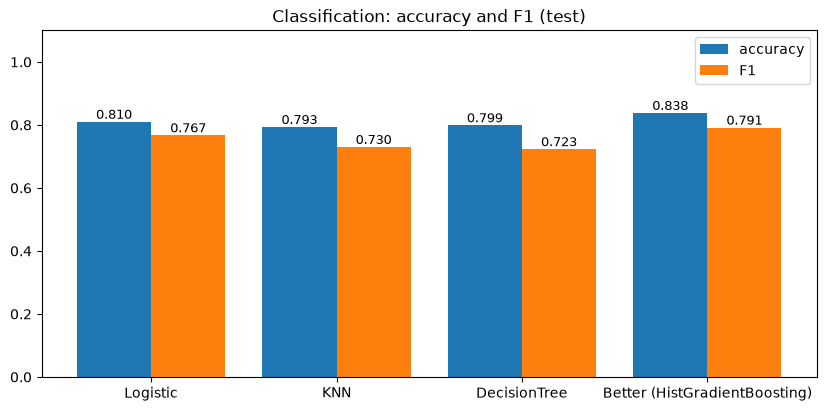

,model,accuracy,F1
1,Better (HistGradientBoosting),0.837989,0.791367
2,Logistic,0.810056,0.767123
3,KNN,0.793296,0.729927
4,DecisionTree,0.798883,0.723077


In [4]:
pos = np.arange(len(cls_pred))
names = list(cls_pred)
acc = [accuracy_score(yc_test, cls_pred[n]) for n in names]
f1s = [f1_score(yc_test, cls_pred[n], average=avg) for n in names]

plt.figure(figsize=(10, 4.5))
b1 = plt.bar(pos - 0.2, acc, 0.4, label="accuracy")
b2 = plt.bar(pos + 0.2, f1s, 0.4, label="F1")
plt.bar_label(b1, fmt="%.3f", fontsize=9)
plt.bar_label(b2, fmt="%.3f", fontsize=9)
plt.xticks(pos, names)
plt.ylim(0, 1.1)
plt.legend()
plt.title("Classification: accuracy and F1 (test)")
plt.show()

cls_rank

## 5. Add the predicted class as a column

In [5]:
best_cls = classifiers[f"Better ({better_name})"]
x_train2, x_test2 = x_train.copy(), x_test.copy()
x_train2["pred_class"] = cross_val_predict(best_cls, x_train, yc_train, cv=5)   # no cheating on train
x_test2["pred_class"] = best_cls.predict(x_test)
x_train2.head()

,Pclass,Sex,Age,SibSp,Parch,pred_class
331,1,1,45.5,0,0,0
733,2,1,23.0,0,0,0
382,3,1,32.0,0,0,1
704,3,1,26.0,1,0,0
813,3,0,6.0,4,2,0


## 6. Regression — pick the Better model (5-fold CV on train)

In [6]:
poly_ridge = make_pipeline(StandardScaler(), PolynomialFeatures(2), Ridge(1))
rf = RandomForestRegressor(300, min_samples_leaf=2, random_state=42)
candidates_r = {
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "RandomForest": rf,
    "Poly2+Ridge": poly_ridge,
    "Forest+Poly2": VotingRegressor([("rf", rf), ("poly", poly_ridge)]),      # average of the two
}
scores_r = {}
for name, m in candidates_r.items():
    scores_r[name] = cross_val_score(m, x_train2, yr_train, cv=5, scoring="r2").mean()
    print(f"{name:18s} CV R2 = {scores_r[name]:.4f}")
better_r = max(scores_r, key=scores_r.get)
print("Better =", better_r)

GradientBoosting   CV R2 = 0.4247


RandomForest       CV R2 = 0.4393
Poly2+Ridge        CV R2 = 0.4962


Forest+Poly2       CV R2 = 0.5082
Better = Forest+Poly2


## 7. Train + predict 4 regressors

In [7]:
corr = x_train2.corrwith(yr_train).abs()
one = corr.idxmax()                                       # Linear uses the 1 most related column
print("Linear uses:", one)

regressors = {
    "Linear": (LinearRegression(), [one]),
    "Multiple": (LinearRegression(), list(x_train2.columns)),
    "Poly": (make_pipeline(PolynomialFeatures(2), LinearRegression()), list(x_train2.columns)),
    f"Better ({better_r})": (candidates_r[better_r], list(x_train2.columns)),
}
reg_pred = {}
for name, (m, c) in regressors.items():
    reg_pred[name] = m.fit(x_train2[c], yr_train).predict(x_test2[c])

Linear uses: Pclass


## 8. Graphs + ranking (regression)

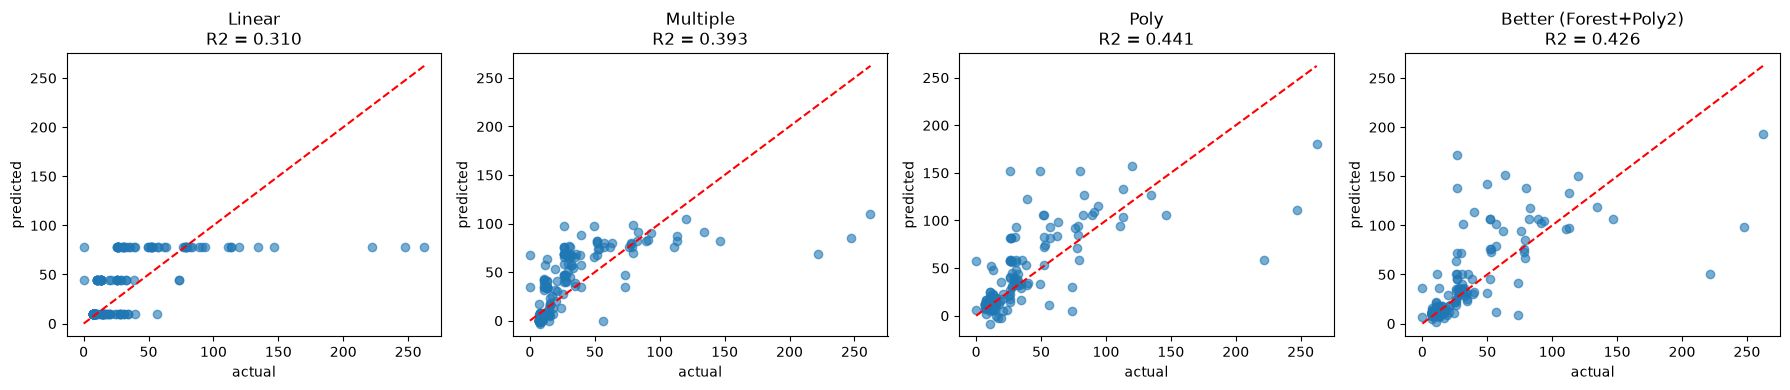

,model,R2
1,Poly,0.440897
2,Better (Forest+Poly2),0.425778
3,Multiple,0.393173
4,Linear,0.309886


In [8]:
plt.figure(figsize=(18, 4))
for i, (name, p) in enumerate(reg_pred.items(), 1):
    plt.subplot(1, 4, i)
    plt.scatter(yr_test, p, alpha=0.6)
    plt.plot([0, yr_test.max()], [0, yr_test.max()], "r--")
    plt.title(f"{name}\nR2 = {r2_score(yr_test, p):.3f}")
    plt.xlabel("actual"); plt.ylabel("predicted")
plt.tight_layout()
plt.show()

reg_rank = pd.DataFrame({"model": list(reg_pred), "R2": [r2_score(yr_test, p) for p in reg_pred.values()]})
reg_rank = reg_rank.sort_values("R2", ascending=False).reset_index(drop=True)
reg_rank.index += 1
reg_rank

**Write under the tables:**
- "Better (…) ranks first for classification (accuracy …, F1 …). It's an ensemble of many trees, so it catches feature interactions. F1 matters when the classes are imbalanced."
- "For regression, Better ranks first (R² …). Adding pred_class gives the model the predicted group of each row."